<a href="https://colab.research.google.com/github/nattaponm/Teach_HID_Doppler_KKN_summerStorm/blob/main/notebooks/04_dualpol_kdp_zdr_attenuation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Notebook 4: เตรียมข้อมูล dual-pol — ΦDP, KDP, ZDR bias และการลดทอนสัญญาณ
### Differential phase processing, specific differential phase, ZDR calibration and Z-PHI attenuation correction

⏱️ เวลาเรียนโดยประมาณ **75 นาที** | ต้องผ่าน: Notebook 1

---
## 🎯 วัตถุประสงค์การเรียนรู้
เมื่อจบ notebook นี้ นิสิตจะสามารถ
1. **ประมวลผล $\Phi_{DP}$ ทีละขั้น**: กลับเครื่องหมาย → คัด gate ฝน → คลายรอยพับเฟส → ลบ system phase → ทำให้เรียบและไม่ลดลง
2. **คำนวณ $K_{DP}$** และอธิบายผลของขนาดหน้าต่างต่อความละเอียดและ noise
3. **แก้ ZDR bias** และอธิบายว่าทำไมต้องแก้ก่อนจำแนกหยาดน้ำฟ้า
4. **แก้การลดทอนสัญญาณ (attenuation)** ของ C-band ด้วยวิธี Z-PHI และประเมินขนาดของผลกระทบหลังแกนพายุ
5. **เตรียม field ที่พร้อมใช้กับ HID ใน NB5** (`DBZ_C`, `ZDR_C`, `KDP`, `temperature`)

## 📖 1. แนวคิดและสมการ

### 1.1 Differential phase
คลื่นแนวนอน (H) ช้ากว่าแนวตั้ง (V) เมื่อผ่านเม็ดฝนแบน → เฟสต่างกันสะสมตามระยะ
$$ \Phi_{DP}(r) = \Phi_{sys} + 2\int_0^{r} K_{DP}(s)\,ds + \delta(r) $$
- $\Phi_{sys}$ = **system phase** (ค่าเริ่มต้นของเครื่อง ~160–175° สำหรับ KKN)
- $\delta$ = backscatter differential phase (สำคัญที่ C-band ในเม็ดฝนใหญ่/ลูกเห็บละลาย)
- เครื่องวัดได้ในช่วง ±180° → **พับเฟส (wrap)** และเครื่องบางรุ่นใช้ **เครื่องหมายกลับ** (KKN: $\Phi_{DP}$ ลดลงตามระยะ)

$$ K_{DP} = \frac{1}{2}\frac{d\Phi_{DP}}{dr}\quad [^\circ\,\mathrm{km^{-1}}] $$
จุดเด่น: ไม่ขึ้นกับการสอบเทียบ Z, ไม่ถูกลดทอน, ไม่ไวต่อลูกเห็บแห้ง → ใช้แยก **ฝนหนัก** ออกจาก **ลูกเห็บ** ได้

### 1.2 การลดทอนที่ C-band
คลื่น C-band (λ ≈ 5.4 cm) อ่อนลงเมื่อผ่านฝนหนัก ทำให้ Z และ ZDR **ด้านหลังแกนพายุต่ำกว่าจริง**
$$ A_H = \alpha\,K_{DP},\qquad A_{DP} = \beta\,K_{DP},\qquad \mathrm{PIA}(r) = 2\int_0^r A_H\,ds \approx \alpha\,[\Phi_{DP}(r) - \Phi_{sys}] $$
C-band: $\alpha \approx 0.07$–$0.08$ dB/°, $\beta \approx 0.02$ dB/° (งานวิจัย KKN ใช้ $a$ = 0.073)

**Z-PHI (Testud et al., 2000)** กระจาย PIA ทั้งหมดของช่วงฝนไปตามระยะตามสัดส่วน $Z^b$
$$ A_H(r) = \frac{Z^{b}(r)\left[10^{0.1 b \alpha \Delta\Phi_{DP}} - 1\right]}{I(r_0, r_1) + \left[10^{0.1 b \alpha \Delta\Phi_{DP}} - 1\right] I(r, r_1)},\qquad I(r, r_1) = 0.46\,b\int_r^{r_1} Z^{b}(s)\,ds $$

### 1.3 ZDR bias
ความต่างเล็กน้อยระหว่างช่อง H และ V ทำให้ $Z_{DR}$ เพี้ยน 0.2–0.5 dB → ใน NB1 พบว่า KKN **ต่ำกว่าจริง** ~0.2–0.4 dB
$$ Z_{DR}^{corr} = Z_{DR}^{obs} + c_{sweep} + \mathrm{PIDA},\qquad c = (+0.20, +0.39, +0.39, +0.39)\ \mathrm{dB} $$
ค่า 0.3 dB ดูเล็ก แต่ฟังก์ชัน membership ของ HID แยก "ฝนเบา" กับ "ผลึกน้ำแข็ง" ด้วยช่วง ZDR แคบ ๆ — ไม่แก้ = จำแนกผิด

## ⚙️ 2. เตรียมสภาพแวดล้อมและข้อมูล

In [1]:
#@title ⚙️ Setup: ติดตั้งแพ็กเกจและดาวน์โหลดข้อมูล (รันก่อนเสมอ ~2–3 นาทีใน Colab)
import os, sys, warnings
warnings.filterwarnings("ignore")

REPO = "Teach_HID_Doppler_KKN_summerStorm"
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    !pip install -q arm_pyart cartopy netCDF4 geopandas metpy cmweather rasterio
    if not os.path.exists(REPO):
        !git clone -q --depth 1 https://github.com/nattaponm/{REPO}.git

for ROOT in [REPO, ".", ".."]:
    if os.path.exists(os.path.join(ROOT, "utils", "polar_tools.py")):
        break
ROOT = os.path.abspath(ROOT)
sys.path.insert(0, ROOT)
DATA = os.path.join(ROOT, "data")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from utils import polar_tools as pt
from utils import mapplot as mp
from utils import kkn_tools as kt
mp.set_style()
mp.set_data_dir(DATA)
print("✅ พร้อมใช้งาน | ข้อมูลอยู่ที่:", DATA)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 14.8/14.8 MB 70.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.5/9.5 MB 71.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.1/10.1 MB 69.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 424.4/424.4 kB 27.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 47.3/47.3 kB 2.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.7/1.7 MB 63.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 326.5/326.5 kB 23.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 221.7/221.7 kB 16.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 157.8/157.8 kB 12.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 56.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 102.6/102.6 kB 8.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.0/16.0 MB 70.3 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currentl

In [2]:
snd = pt.load_profile(os.path.join(DATA, "sounding", "sounding_48431_2024-05-03_00Z.csv"))
peak = pt.polar_files(DATA, "09:00", "10:45")
radar = pt.read_volume(pt.polar_files(DATA, "09:30", "09:30")[0])
meta = pt.polar_meta(radar)
reports = kt.load_reports(DATA, meta)
NK = kt.site(reports, "Na Klang")
NW = kt.box_around(meta, 102.3, 17.3, 90)
pt.add_temperature(radar, snd)
print(mp.tlabel(pt.volume_time(radar)))

09:30 UTC (16:30 LT)


## 🔬 3. ประมวลผล ΦDP ทีละขั้น ตามแนวลำคลื่นหนึ่งเส้น

In [3]:
radar, steps, sign, sysp = pt.process_phidp(radar, return_steps=True)
print("เครื่องหมายที่ใช้ (ตรวจอัตโนมัติจากความชัน) :", sign)
print("system phase ราย sweep (°)               :", {k: round(v, 1) for k, v in sysp.items()})
pt.add_kdp(radar)                                  # Vulpiani et al. (2012), windsize = 10 gate (5 km)

# เลือก ray ที่ผ่านแกนพายุใกล้นากลาง (มุมยก 1.48°)
az_nk, rng_nk = pt.azimuth_to(meta, NK["lon"], NK["lat"])
sl = radar.get_slice(1)
az1 = radar.azimuth["data"][sl]
z1 = pt.field_data(radar, "reflectivity_qc", 1)
cand = np.where(np.abs((az1 - az_nk + 180) % 360 - 180) < 15)[0]
iray = sl.start + cand[np.argmax(np.nansum(z1[cand] > 35, axis=1))]
rk = radar.range["data"] / 1000
print(f"ray ที่เลือก: azimuth {radar.azimuth['data'][iray]:.1f}°, นากลางอยู่ที่ azimuth {az_nk:.1f}°, ระยะ {rng_nk:.0f} km")

เครื่องหมายที่ใช้ (ตรวจอัตโนมัติจากความชัน) : {0: -1.0, 1: -1.0, 2: -1.0, 3: -1.0}
system phase ราย sweep (°)               : {0: 159.9, 1: 159.9, 2: 159.9, 3: 159.9}
ray ที่เลือก: azimuth 337.3°, นากลางอยู่ที่ azimuth 335.3°, ระยะ 114 km


บันทึกรูปแล้ว: figures/nb4_phidp_steps.png, figures/nb4_phidp_steps.pdf


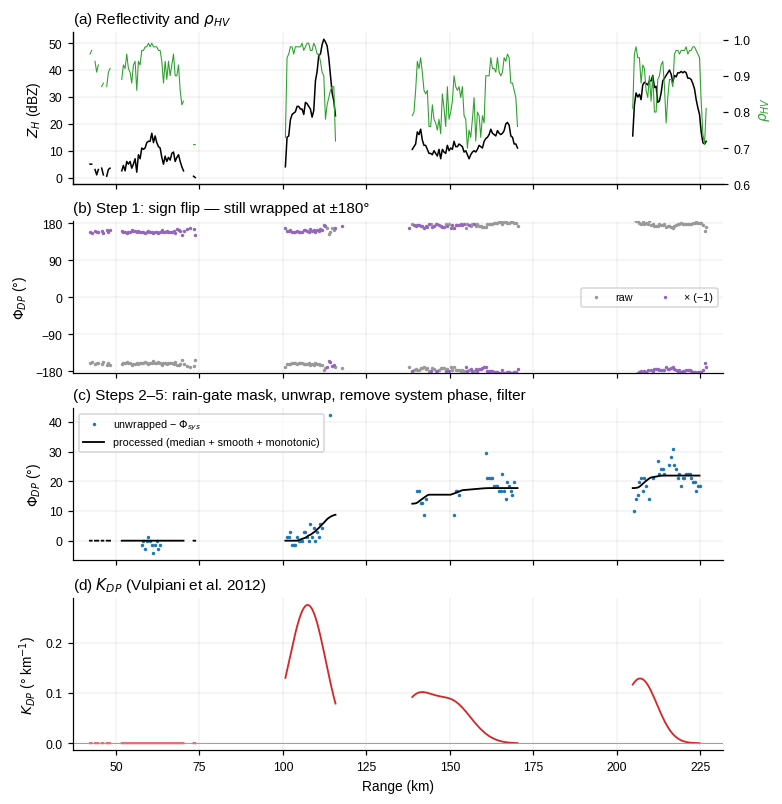

In [4]:
fig, axs = plt.subplots(4, 1, figsize=(7, 7.2), sharex=True, layout="constrained")
axs[0].plot(rk, pt.field_data(radar, "reflectivity_qc")[iray], "k", lw=1, label="$Z_H$")
ax0b = axs[0].twinx()
ax0b.plot(rk, pt.field_data(radar, "cross_correlation_ratio_qc")[iray], color="tab:green", lw=0.7)
ax0b.set_ylabel("$\\rho_{HV}$", color="tab:green"); ax0b.set_ylim(0.6, 1.02)
axs[0].set_ylabel("$Z_H$ (dBZ)"); axs[0].set_title("(a) Reflectivity and $\\rho_{HV}$", loc="left")
axs[1].plot(rk, steps["raw"][iray], ".", ms=2.5, color="0.6", label="raw")
axs[1].plot(rk, steps["signed"][iray], ".", ms=2.5, color="tab:purple", label="× (−1)")
axs[1].set_ylim(-185, 185); axs[1].set_yticks([-180, -90, 0, 90, 180]); axs[1].legend(fontsize=7, ncol=2)
axs[1].set_ylabel("$\\Phi_{DP}$ (°)"); axs[1].set_title("(b) Step 1: sign flip — still wrapped at ±180°", loc="left")
axs[2].plot(rk, steps["unwrapped"][iray], ".", ms=2.5, color="tab:blue", label="unwrapped − $\\Phi_{sys}$")
axs[2].plot(rk, steps["processed"][iray], "k-", lw=1.2, label="processed (median + smooth + monotonic)")
axs[2].set_ylabel("$\\Phi_{DP}$ (°)"); axs[2].legend(fontsize=7)
axs[2].set_title("(c) Steps 2–5: rain-gate mask, unwrap, remove system phase, filter", loc="left")
axs[3].plot(rk, pt.field_data(radar, "KDP")[iray], color="tab:red", lw=1.2)
axs[3].axhline(0, color="0.6", lw=0.6); axs[3].set_ylabel("$K_{DP}$ (° km$^{-1}$)"); axs[3].set_xlabel("Range (km)")
axs[3].set_title("(d) $K_{DP}$ (Vulpiani et al. 2012)", loc="left")
for ax in axs:
    ax.grid(lw=0.3, alpha=0.5)
valid = np.where(np.isfinite(steps["raw"][iray]))[0]
axs[3].set_xlim(max(0, rk[valid[0]] - 5), rk[valid[-1]] + 5)
mp.save_figure(fig, "nb4_phidp_steps")
plt.show()

- (b) หลังคูณ −1 ค่าเริ่มที่ ~+170° (system phase) แล้ว "ข้าม" ไปเป็น −180° — นี่คือรอยพับ ไม่ใช่การลดลงจริง
- (c) หลังคลายเฟสและลบ system phase ได้ $\Phi_{DP}$ ที่ **เริ่มจาก 0 และเพิ่มขึ้นเมื่อผ่านแกนฝน** ตามทฤษฎี
- (d) $K_{DP}$ สูงตรงกับช่วงที่ $\Phi_{DP}$ ชันที่สุด = ฝนหนัก/น้ำเหลวมาก
- บริเวณที่ไม่มีฝน ระหว่างเซลล์ ค่าที่ประมวลผลแล้ว **คงที่** (ไม่ลดลง) เพราะไม่มีน้ำเหลวเพิ่ม

## 🗺️ 4. แผนที่ ΦDP ก่อน–หลัง และ KDP

บันทึกรูปแล้ว: figures/nb4_phidp_kdp_pia_maps.png, figures/nb4_phidp_kdp_pia_maps.pdf


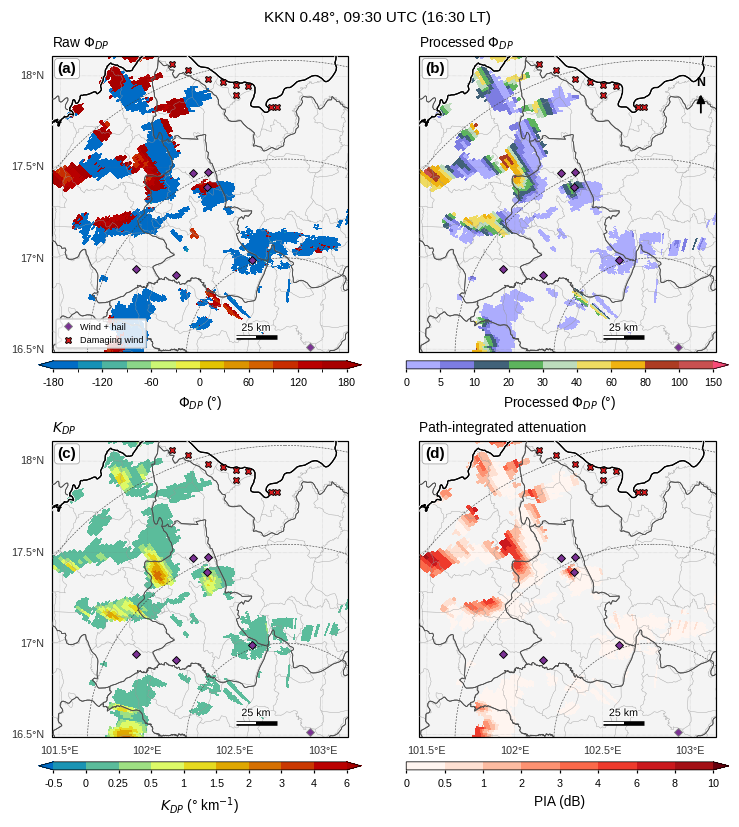

In [5]:
pt.correct_zdr_bias(radar)          # ZDR_C0 = ZDR + (0.20, 0.39, 0.39, 0.39)
pt.correct_attenuation(radar)       # DBZ_C, ZDR_C, PIA
panels = [("differential_phase_qc", "PHI", "Raw $\\Phi_{DP}$"), ("PHIDP", "PHIP", "Processed $\\Phi_{DP}$"),
          ("KDP", "KDP", "$K_{DP}$"), ("PIA", "PIA", "Path-integrated attenuation")]
fig, axs = mp.map_panels(2, 2, meta, panel_width=3.4, zoom=NW)
for k, (ax, (f, kind, ttl)) in enumerate(zip(axs, panels)):
    im = pt.ppi_map(ax, radar, f, 0, meta, kind=kind, zoom=NW, title=ttl, north=(k == 1),
                    gridline_labels=(("left",) if k % 2 == 0 else ()) + (("bottom",) if k >= 2 else ()))
    mp.add_reports(ax, reports, legend=(k == 0), ms=4)
    mp.add_colorbar(fig, im, ax, shrink=0.9, extend="both" if kind in ("PHI", "KDP") else "max")
mp.panel_labels(axs)
fig.suptitle(f"KKN 0.48°, {mp.tlabel(pt.volume_time(radar))}", fontsize=10)
mp.save_figure(fig, "nb4_phidp_kdp_pia_maps")
plt.show()

- (a) ค่าดิบเกือบทั้งหมดอยู่ใกล้ ±180° (system phase) จึงแทบมองไม่เห็นสัญญาณ
- (b) หลังประมวลผล $\Phi_{DP}$ **เพิ่มขึ้นตามระยะ** เป็นแถบ "เงา" ด้านหลังแกนพายุ (มองจากเรดาร์ซึ่งอยู่ทางตะวันออกเฉียงใต้)
- (c) $K_{DP}$ สูงเฉพาะแกนฝน — (d) PIA คือ dB ที่ Z หายไประหว่างทาง ซึ่ง **สะสมไปด้านหลังพายุ**

## 🎚️ 5. ผลของการแก้ ZDR bias และการลดทอน

บันทึกรูปแล้ว: figures/nb4_correction_maps.png, figures/nb4_correction_maps.pdf


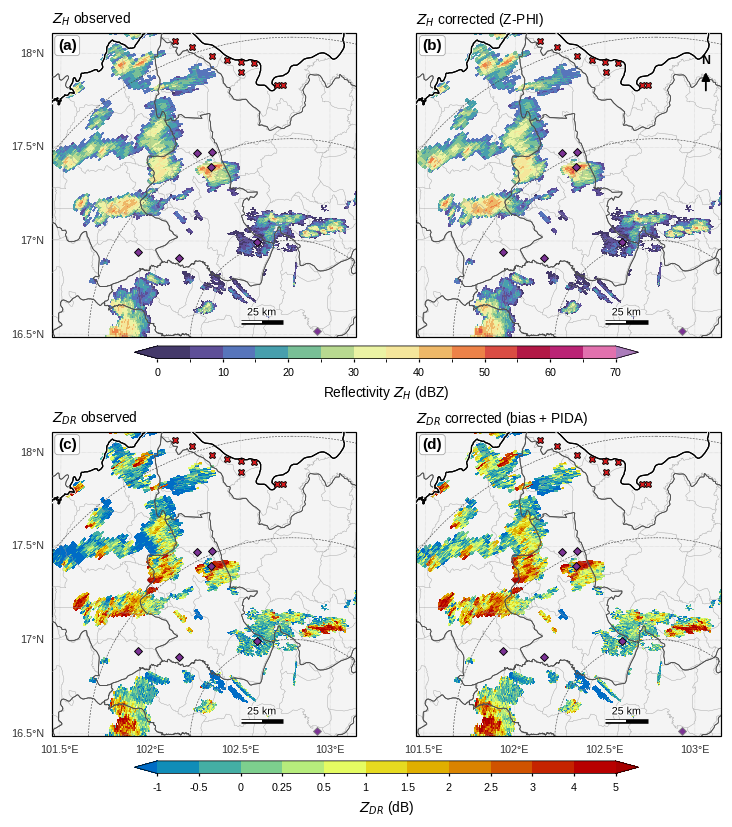

การแก้ Z: p95 = 2.7 dB, max = 9.1 dB
จำนวน gate ≥ 50 dBZ (0.48°): ก่อนแก้ 23 → หลังแก้ 40


In [6]:
panels = [("reflectivity_qc", "Z", "$Z_H$ observed"), ("DBZ_C", "Z", "$Z_H$ corrected (Z-PHI)"),
          ("differential_reflectivity_qc", "ZDR", "$Z_{DR}$ observed"), ("ZDR_C", "ZDR", "$Z_{DR}$ corrected (bias + PIDA)")]
fig, axs = mp.map_panels(2, 2, meta, panel_width=3.4, zoom=NW)
for k, (ax, (f, kind, ttl)) in enumerate(zip(axs, panels)):
    im = pt.ppi_map(ax, radar, f, 0, meta, kind=kind, zoom=NW, title=ttl, north=(k == 1),
                    gridline_labels=(("left",) if k % 2 == 0 else ()) + (("bottom",) if k >= 2 else ()))
    mp.add_reports(ax, reports, legend=False, ms=4)
    if k % 2 == 1:
        mp.add_colorbar(fig, im, axs[k - 1:k + 1], shrink=0.7, extend="both")
mp.panel_labels(axs)
mp.save_figure(fig, "nb4_correction_maps")
plt.show()
dz = pt.field_data(radar, "DBZ_C") - pt.field_data(radar, "reflectivity_qc")
m50o = np.nansum(pt.field_data(radar, "reflectivity_qc", 0) >= 50)
m50c = np.nansum(pt.field_data(radar, "DBZ_C", 0) >= 50)
print(f"การแก้ Z: p95 = {np.nanpercentile(dz[dz > 0], 95):.1f} dB, max = {np.nanmax(dz):.1f} dB")
print(f"จำนวน gate ≥ 50 dBZ (0.48°): ก่อนแก้ {m50o} → หลังแก้ {m50c}")

## 📈 6. ตรวจความสมเหตุสมผลทางกายภาพ (self-consistency)

บันทึกรูปแล้ว: figures/nb4_self_consistency.png, figures/nb4_self_consistency.pdf


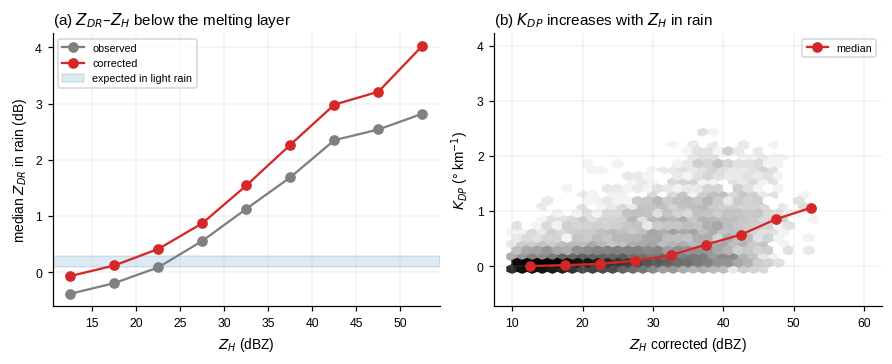

In [7]:
z_c, zdr_c, kdp = (pt.field_data(radar, f) for f in ("DBZ_C", "ZDR_C", "KDP"))
zdr_o = pt.field_data(radar, "differential_reflectivity_qc")
rain = (radar.gate_altitude["data"] < pt.isotherm_height(snd, 0) - 1000) & \
       (pt.field_data(radar, "cross_correlation_ratio_qc") > 0.9) & np.isfinite(z_c)
zb = np.arange(10, 61, 5)
fig, axs = plt.subplots(1, 2, figsize=(8, 3.2), layout="constrained")
for arr, lab, col in ((zdr_o, "observed", "0.5"), (zdr_c, "corrected", "tab:red")):
    md = [np.nanmedian(arr[rain & (z_c >= a) & (z_c < a + 5)]) for a in zb[:-1]]
    axs[0].plot(zb[:-1] + 2.5, md, "o-", color=col, label=lab)
axs[0].axhspan(0.1, 0.3, color="tab:blue", alpha=0.15, label="expected in light rain")
axs[0].set_xlabel("$Z_H$ (dBZ)"); axs[0].set_ylabel("median $Z_{DR}$ in rain (dB)"); axs[0].legend(fontsize=7)
axs[0].set_title("(a) $Z_{DR}$–$Z_H$ below the melting layer", loc="left")
ok = rain & np.isfinite(kdp)
axs[1].hexbin(z_c[ok], kdp[ok], gridsize=35, bins="log", cmap="Greys", mincnt=1, extent=(10, 60, -0.5, 4))
mk = [np.nanmedian(kdp[ok & (z_c >= a) & (z_c < a + 5)]) for a in zb[:-1]]
axs[1].plot(zb[:-1] + 2.5, mk, "o-", color="tab:red", label="median")
axs[1].set_xlabel("$Z_H$ corrected (dBZ)"); axs[1].set_ylabel("$K_{DP}$ (° km$^{-1}$)"); axs[1].legend(fontsize=7)
axs[1].set_title("(b) $K_{DP}$ increases with $Z_H$ in rain", loc="left")
for ax in axs:
    ax.grid(lw=0.3, alpha=0.5)
mp.save_figure(fig, "nb4_self_consistency")
plt.show()

- (a) หลังแก้ ZDR ในฝนเบา (20–28 dBZ) เข้าใกล้ค่าที่ควรเป็น (~0.2 dB) และเพิ่มตาม Z (เม็ดใหญ่ขึ้น) ตามทฤษฎี
- (b) $K_{DP}$ แทบเป็นศูนย์เมื่อ Z < 35 dBZ และเพิ่มขึ้นเร็วเมื่อ Z > 40 dBZ — สอดคล้องกับธรรมชาติของฝนหนัก
  ถ้าพบ Z สูงมากแต่ $K_{DP}$ ต่ำ → อาจเป็น **ลูกเห็บแห้ง** (Z สูงแต่ไม่แบน) — ข้อมูลนี้คือหัวใจของ HID ใน NB5

---
## 🧪 แบบฝึกหัด

### 🧪 แบบฝึกหัด 4.1: ทุกมุมยกต้องกลับเครื่องหมาย ΦDP หรือไม่?
งานวิจัยเดิมของ KKN พบว่า **บาง sweep** มีเครื่องหมายกลับ ใช้ `pt.phidp_slope_by_sweep(r)` กับทั้ง 8 volume ใน `peak`
แล้วสรุปความชันมัธยฐาน และจำนวน ray ที่ใช้ได้ของแต่ละ sweep

**คำถาม:** ผลสอดคล้องกันทุกเวลาหรือไม่? ถ้าใส่เครื่องหมายผิด $K_{DP}$ และ PIA จะเป็นอย่างไร?

<details>
<summary><b>💡 คำใบ้</b></summary>

- ผลคืน dict `{sweep: (slope_deg_per_km, n_rays)}`
- `pd.DataFrame(rows).pivot(index="time", columns="sweep", values="slope")`
- ทดลองใส่เครื่องหมายผิด: `pt.process_phidp(r, sign=+1.0)` แล้วดู `KDP`

</details>

In [8]:
# ✍️ แบบฝึกหัด 4.1 — เขียนโค้ดของคุณที่นี่

In [9]:
#@title ✅ เฉลยแบบฝึกหัด 4.1
rows = []
for f in peak:
    r = pt.read_volume(f)
    for s, (sl_, n) in pt.phidp_slope_by_sweep(r).items():
        rows.append({"time": pt.volume_time(r).strftime("%H:%M"), "sweep": s, "slope": sl_, "n_rays": n})
sg = pd.DataFrame(rows)
print("ความชัน ΦDP ดิบ (°/km) — ค่าลบ = ต้องกลับเครื่องหมาย")
print(sg.pivot(index="time", columns="sweep", values="slope").round(2))
print("\nจำนวน ray ที่ใช้ได้รวม:", sg.groupby("sweep")["n_rays"].sum().to_dict())
neg = (sg.dropna().groupby("sweep")["slope"].apply(lambda x: np.mean(x < 0) * 100)).round(0)
print("ร้อยละของเวลาที่ความชันเป็นลบ:", neg.to_dict())
# ลองใส่เครื่องหมายผิด
r = pt.read_volume(pt.polar_files(DATA, "09:30", "09:30")[0])
pt.process_phidp(r, sign=+1.0, name="PHIDP_wrong"); pt.add_kdp(r, phidp="PHIDP_wrong", name="KDP_wrong")
pt.process_phidp(r); pt.add_kdp(r)
print(f"\nKDP p99 เครื่องหมายถูก = {np.nanpercentile(pt.field_data(r, 'KDP'), 99):.2f} | ผิด = {np.nanpercentile(pt.field_data(r, 'KDP_wrong'), 99):.2f} °/km")
print("→ ในข้อมูลชุดนี้ทุก sweep ลดลงตามระยะ (กลับเครื่องหมายทั้งหมด) — ต่างจากข้อสังเกตเดิมที่ว่าเป็นบาง sweep"
      "\n  อาจเพราะไฟล์ที่ผ่านการเตรียมข้อมูลต่างกัน จึงควรตรวจเครื่องหมายอัตโนมัติทุก volume แทนการกำหนดตายตัว"
      "\n  ถ้าเครื่องหมายผิด ΦDP ที่ถูกบังคับให้ไม่ลดลงจะ 'แบน' เกือบทั้งเส้น → KDP ≈ 0 และ PIA ถูกประเมินต่ำ")

ความชัน ΦDP ดิบ (°/km) — ค่าลบ = ต้องกลับเครื่องหมาย
sweep     0     1     2     3
time                         
09:00 -0.36 -0.24 -0.34 -2.89
09:15 -0.65 -0.50 -0.34 -0.29
09:30 -0.18 -1.30 -0.58 -0.44
09:45 -1.89 -1.34 -0.34 -0.25
10:00 -0.54 -0.66 -0.20 -0.27
10:15 -1.15 -2.11 -0.74 -0.09
10:30 -1.14 -1.41 -0.14 -0.06
10:45 -1.34 -0.26 -0.32  0.15

จำนวน ray ที่ใช้ได้รวม: {0: 122, 1: 152, 2: 96, 3: 79}
ร้อยละของเวลาที่ความชันเป็นลบ: {0: 100.0, 1: 100.0, 2: 100.0, 3: 88.0}

KDP p99 เครื่องหมายถูก = 1.60 | ผิด = 0.05 °/km
→ ในข้อมูลชุดนี้ทุก sweep ลดลงตามระยะ (กลับเครื่องหมายทั้งหมด) — ต่างจากข้อสังเกตเดิมที่ว่าเป็นบาง sweep
  อาจเพราะไฟล์ที่ผ่านการเตรียมข้อมูลต่างกัน จึงควรตรวจเครื่องหมายอัตโนมัติทุก volume แทนการกำหนดตายตัว
  ถ้าเครื่องหมายผิด ΦDP ที่ถูกบังคับให้ไม่ลดลงจะ 'แบน' เกือบทั้งเส้น → KDP ≈ 0 และ PIA ถูกประเมินต่ำ


### 🧪 แบบฝึกหัด 4.2: ขนาดหน้าต่างของ KDP
คำนวณ KDP ด้วย `pt.add_kdp(radar, windsize=W, name=f"KDP_{W}")` สำหรับ W = 6, 10, 20 gate (3, 5, 10 km)
และวิธีความชันอย่างง่าย `method="slope"` (W = 10) แล้วเปรียบเทียบ (1) ค่า p99, ค่าสูงสุด และ "noise" (ส่วนเบี่ยงเบนมาตรฐานของ KDP ในฝนเบา Z < 30 dBZ ซึ่งควรเป็น ~0) (2) กราฟตามแนว ray `iray`

**คำถาม:** หน้าต่างใหญ่/เล็กเหมาะกับงานแบบไหน (เช่น ประมาณฝน vs หาแกนลูกเห็บขนาดเล็ก)?

<details>
<summary><b>💡 คำใบ้</b></summary>

- noise: `np.nanstd(k[(z < 30) & np.isfinite(k)])` โดย `z = pt.field_data(radar, "reflectivity_qc")`
- พลอต: `plt.plot(rk, pt.field_data(radar, f"KDP_{W}")[iray])`

</details>

In [10]:
# ✍️ แบบฝึกหัด 4.2 — เขียนโค้ดของคุณที่นี่

บันทึกรูปแล้ว: figures/nb4_ex42_kdp_window.png, figures/nb4_ex42_kdp_window.pdf


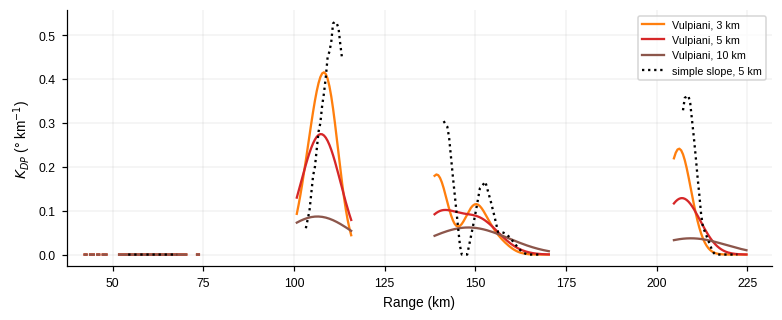

                p99   max  noise_sd_lightrain
vulpiani W=6   2.08  3.98                0.19
vulpiani W=10  1.60  2.75                0.15
vulpiani W=20  0.86  1.49                0.10
slope W=10     2.82  5.56                0.20

(ไม่มีค่าติดลบ เพราะ ΦDP ที่ประมวลผลถูกบังคับให้ไม่ลดลงตามระยะ — เป็นข้อแลกเปลี่ยนที่ซ่อน noise ไว้ในรูปยอดแหลมแทน)
→ หน้าต่างเล็ก: ตอบสนองแกนพายุแคบ ๆ ได้ (ค่าสูงสุดสูง) แต่ noise มาก | หน้าต่างใหญ่: เรียบ แต่ลดยอดและทำให้แกนกว้างเกินจริง
  ประมาณฝนสะสม → หน้าต่างใหญ่พอสมควร ; หาแกนฝนหนัก/ลูกเห็บขนาด 2–5 km → หน้าต่างเล็ก + ระวัง δ (backscatter phase)


In [11]:
#@title ✅ เฉลยแบบฝึกหัด 4.2
res = {}
zq = pt.field_data(radar, "reflectivity_qc")
light = zq < 30
fig, ax = plt.subplots(figsize=(7, 2.8), layout="constrained")
for W, col in ((6, "tab:orange"), (10, "tab:red"), (20, "tab:brown")):
    pt.add_kdp(radar, windsize=W, name=f"KDP_{W}")
    k = pt.field_data(radar, f"KDP_{W}")
    res[f"vulpiani W={W}"] = {"p99": np.nanpercentile(k, 99), "max": np.nanmax(k), "noise_sd_lightrain": np.nanstd(k[light])}
    ax.plot(rk, k[iray], color=col, label=f"Vulpiani, {W * 0.5:g} km")
pt.add_kdp(radar, windsize=10, method="slope", name="KDP_slope")
k = pt.field_data(radar, "KDP_slope")
res["slope W=10"] = {"p99": np.nanpercentile(k, 99), "max": np.nanmax(k), "noise_sd_lightrain": np.nanstd(k[light])}
ax.plot(rk, k[iray], "k:", label="simple slope, 5 km")
ax.set_xlim(max(0, rk[valid[0]] - 5), rk[valid[-1]] + 5)
ax.set_xlabel("Range (km)"); ax.set_ylabel("$K_{DP}$ (° km$^{-1}$)"); ax.legend(fontsize=7); ax.grid(lw=0.3, alpha=0.5)
mp.save_figure(fig, "nb4_ex42_kdp_window")
plt.show()
print(pd.DataFrame(res).T.round(2))
print("\n(ไม่มีค่าติดลบ เพราะ ΦDP ที่ประมวลผลถูกบังคับให้ไม่ลดลงตามระยะ — เป็นข้อแลกเปลี่ยนที่ซ่อน noise ไว้ในรูปยอดแหลมแทน)")
print("→ หน้าต่างเล็ก: ตอบสนองแกนพายุแคบ ๆ ได้ (ค่าสูงสุดสูง) แต่ noise มาก | หน้าต่างใหญ่: เรียบ แต่ลดยอดและทำให้แกนกว้างเกินจริง"
      "\n  ประมาณฝนสะสม → หน้าต่างใหญ่พอสมควร ; หาแกนฝนหนัก/ลูกเห็บขนาด 2–5 km → หน้าต่างเล็ก + ระวัง δ (backscatter phase)")

### 🧪 แบบฝึกหัด 4.3: การลดทอนที่นากลางมากแค่ไหน และเปลี่ยนข้อสรุปเรื่องลูกเห็บหรือไม่?
สำหรับ 8 volume ใน `peak` จงหา (1) PIA สูงสุดในรัศมี 15 km รอบนากลาง (มุมยก 0.48°) (2) Z สูงสุดก่อน–หลังแก้ (3) พื้นที่ (จำนวน gate) ที่ Z ≥ 50 dBZ ก่อน–หลังแก้

**คำถาม:** ถ้าไม่แก้การลดทอน จะประเมินความรุนแรงของพายุต่ำไปกี่ dB? เหตุใดการลดทอนจึงมากเป็นพิเศษในพายุที่มีลูกเห็บละลาย?

<details>
<summary><b>💡 คำใบ้</b></summary>

- ขั้นตอน: `pt.add_temperature(r, snd); pt.process_phidp(r); pt.add_kdp(r); pt.correct_zdr_bias(r); pt.correct_attenuation(r)`
- mask รอบจุด: `pt.site_gates(r, meta, NK["lon"], NK["lat"], 15, sweeps=[0])`

</details>

In [12]:
# ✍️ แบบฝึกหัด 4.3 — เขียนโค้ดของคุณที่นี่

In [13]:
#@title ✅ เฉลยแบบฝึกหัด 4.3
rows = []
for f in peak:
    r = pt.read_volume(f)
    pt.add_temperature(r, snd); pt.process_phidp(r); pt.add_kdp(r); pt.correct_zdr_bias(r); pt.correct_attenuation(r)
    m = pt.site_gates(r, meta, NK["lon"], NK["lat"], 15, sweeps=[0])
    zo, zc, pia = (pt.field_data(r, k) for k in ("reflectivity_qc", "DBZ_C", "PIA"))
    rows.append({"time_UTC": pt.volume_time(r).strftime("%H:%M"), "PIA_max_dB": np.nanmax(pia[m]) if np.isfinite(pia[m]).any() else np.nan,
                 "Zmax_obs": np.nanmax(zo[m]), "Zmax_corr": np.nanmax(zc[m]),
                 "gates_Z50_obs": int(np.nansum(zo[m] >= 50)), "gates_Z50_corr": int(np.nansum(zc[m] >= 50))})
at = pd.DataFrame(rows).set_index("time_UTC").round(1)
print(at)
print(f"\n→ PIA รอบนากลางสูงสุด {at['PIA_max_dB'].max():.1f} dB ; Z สูงสุดเพิ่มขึ้นเฉลี่ย {(at['Zmax_corr'] - at['Zmax_obs']).mean():.1f} dB หลังแก้"
      f"\n  gate ≥ 50 dBZ รวม 8 เวลา: {at['gates_Z50_obs'].sum()} → {at['gates_Z50_corr'].sum()}")
print("  ลูกเห็บที่ละลายมีผิวเป็นน้ำ ขนาดใหญ่ → ทั้งลดทอนและให้ δ สูงที่ C-band (resonance) ทำให้ ΦDP/KDP และ PIA สูงผิดปกติ"
      "\n  ⚠️ ถ้า ΦDP มี δ ปน Z-PHI อาจแก้ 'เกิน' — งานวิจัยควรตรวจกับเรดาร์ข้างเคียงหรือข้อมูลภาคพื้นดิน")

          PIA_max_dB  Zmax_obs  Zmax_corr  gates_Z50_obs  gates_Z50_corr
time_UTC                                                                
09:00            3.4      49.5       52.1              0               2
09:15            4.3      50.5       51.1              1               1
09:30            5.2      51.5       52.1              3               8
09:45            6.3      53.5       56.0              8              27
10:00            4.4      49.0       50.7              0               3
10:15            4.7      46.0       46.5              0               0
10:30            3.3      41.0       44.3              0               0
10:45            0.8      41.5       42.2              0               0

→ PIA รอบนากลางสูงสุด 6.3 dB ; Z สูงสุดเพิ่มขึ้นเฉลี่ย 1.6 dB หลังแก้
  gate ≥ 50 dBZ รวม 8 เวลา: 12 → 41
  ลูกเห็บที่ละลายมีผิวเป็นน้ำ ขนาดใหญ่ → ทั้งลดทอนและให้ δ สูงที่ C-band (resonance) ทำให้ ΦDP/KDP และ PIA สูงผิดปกติ
  ⚠️ ถ้า ΦDP มี δ ปน Z-PHI อาจแก้ 'เกิน' — งา

---
## 📝 สรุป
- $\Phi_{DP}$ ของ KKN ต้อง **กลับเครื่องหมาย คลายรอยพับ และลบ system phase (~160–175°)** ก่อนใช้งาน — ตรวจอัตโนมัติด้วยความชันตามระยะ
- $K_{DP}$ (Vulpiani) ให้ค่าที่สมเหตุสมผลกับ Z ในฝน และขนาดหน้าต่างเป็นการแลกเปลี่ยนระหว่างความละเอียดกับ noise
- การลดทอนที่ C-band ใน **แกนพายุ 3 พ.ค. มีขนาดหลาย dB** — ต้องแก้ก่อนประเมินความรุนแรงหรือใช้ HID
- ZDR ต้องแก้ bias (+0.2 ถึง +0.4 dB) และการลดทอน (PIDA) → ได้ `DBZ_C`, `ZDR_C`, `KDP` พร้อมใช้ใน NB5

### ❓ คำถามชวนคิด
1. ทำไม $K_{DP}$ จึงไม่ถูกกระทบจากการลดทอนและการสอบเทียบ Z? ข้อดีนี้สำคัญอย่างไรกับเรดาร์ C-band ในเขตร้อน
2. ถ้า $\rho_{HV}$ ในฝนของ KKN ต่ำ (~0.95) จะกระทบขั้น "คัด gate ฝน" อย่างไร? ควรปรับเกณฑ์ 0.85 หรือไม่
3. ในงานวิจัยที่ต้องประมาณฝนสะสมของพายุนี้ ควรใช้ R(Z), R(KDP) หรือผสมกัน เพราะอะไร?

**🚀 ต่อยอด (ป.โท):** ทำความสัมพันธ์ $R(K_{DP})$ และ $R(Z, Z_{DR})$ แล้วเทียบฝนสะสม 12:00–24:00 น. กับสถานีวัดฝนของกรมอุตุนิยมวิทยา/กรมชลประทานในหนองบัวลำภู

### 📚 เอกสารอ้างอิง
- Testud, J., Le Bouar, E., Obligis, E., & Ali-Mehenni, M. (2000). The rain profiling algorithm applied to polarimetric weather radar. *J. Atmos. Oceanic Technol.*, 17, 332–356.
- Vulpiani, G., Montopoli, M., Passeri, L. D., Gioia, A. G., Giordano, P., & Marzano, F. S. (2012). On the use of dual-polarized C-band radar for operational rainfall retrieval in mountainous areas. *J. Appl. Meteor. Climatol.*, 51, 405–425.
- Bringi, V. N., & Chandrasekar, V. (2001). *Polarimetric Doppler Weather Radar: Principles and Applications*. Cambridge University Press.
- Ryzhkov, A. V., & Zrnić, D. S. (2019). *Radar Polarimetry for Weather Observations*. Springer.
- Gourley, J. J., Tabary, P., & Parent du Chatelet, J. (2007). A fuzzy logic algorithm for the separation of precipitating from nonprecipitating echoes using polarimetric radar observations. *J. Atmos. Oceanic Technol.*, 24, 1439–1451.